In [ ]:
!pip install -q nltk gensim

In [ ]:
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, auc
)

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [ ]:
df=pd.read_csv('/content/drive/MyDrive/ML_AL/Preprocessed_DonorsChoose_dataset.csv')
df.head()

,id,teacher_prefix,school_state,project_grade_category,project_subject_categories,project_subject_subcategories,teacher_number_of_previously_posted_projects,project_is_approved,price,quantity,cleaned_titles,cleaned_essays,cleaned_summary,isdigit_summary
0,p253737,mrs,in,grades_prek_2,literacy_language,esl_literacy,0,0,154.60,23,educational support english learners home,students english learners working english seco...,students_need_opportunities_practice_beginning...,0
1,p258326,mr,fl,grades_6_8,history_civics_health_sports,civics_government_teamsports,7,1,299.00,1,wanted projector hungry learners,students arrive school eager learn polite gene...,students_need_projector_help_viewing_education...,0
2,p182444,ms,az,grades_6_8,health_sports,health_wellness_teamsports,1,0,516.85,22,soccer equipment awesome middle school students,true champions not always ones win guts mia ha...,students_need_shine_guards_athletic_socks_socc...,0
3,p246581,mrs,ky,grades_prek_2,literacy_language_math_science,literacy_mathematics,4,1,232.90,4,techie kindergarteners,work unique school filled esl english second l...,students_need_engage_reading_math_way_inspire_...,0
4,p104768,mrs,tx,grades_prek_2,math_science,mathematics,1,1,67.98,4,interactive math tools,second grade classroom next year made around 2...,students_need_hands_practice_mathematics_fun_p...,0


In [ ]:
#data exploration
print("Shape:", df.shape)

print("Column names:",df.columns)

print("Data types:",df.dtypes)

print("Missing values:",df.isnull().sum())

print("Statistical summary:",df.describe)

Shape: (109248, 14)
Column names: Index(['id', 'teacher_prefix', 'school_state', 'project_grade_category',
       'project_subject_categories', 'project_subject_subcategories',
       'teacher_number_of_previously_posted_projects', 'project_is_approved',
       'price', 'quantity', 'cleaned_titles', 'cleaned_essays',
       'cleaned_summary', 'isdigit_summary'],
      dtype='object')
Data types: id                                               object
teacher_prefix                                   object
school_state                                     object
project_grade_category                           object
project_subject_categories                       object
project_subject_subcategories                    object
teacher_number_of_previously_posted_projects      int64
project_is_approved                               int64
price                                           float64
quantity                                          int64
cleaned_titles                           

In [ ]:
#target distribution
print(df['project_is_approved'].value_counts())
print("\nPercentage distribution:")
print(df['project_is_approved'].value_counts(normalize=True) * 100)

project_is_approved
1    92706
0    16542
Name: count, dtype: int64

Percentage distribution:
project_is_approved
1    84.858304
0    15.141696
Name: proportion, dtype: float64


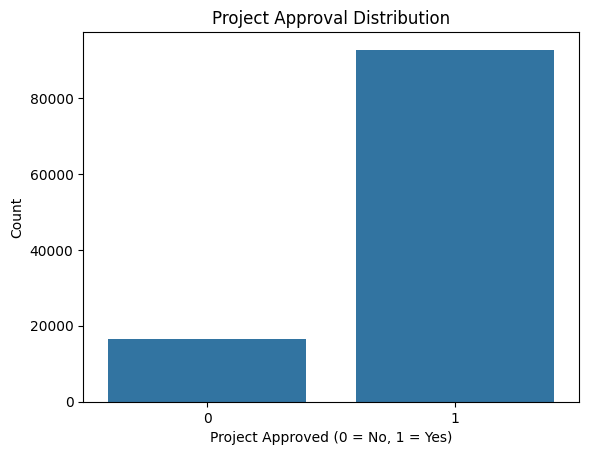

In [ ]:
#target visualization
sns.countplot(x='project_is_approved', data=df)

plt.title("Project Approval Distribution")
plt.xlabel("Project Approved (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

In [ ]:
#explore text problems
text_columns = ['cleaned_titles','cleaned_essays','cleaned_summary']
for column in text_columns:
    print("\nColumn:", column)
    print(df[column].head())
    print("Average text length:",
          df[column].fillna('').astype(str).str.len().mean())


Column: cleaned_titles
0          educational support english learners home
1                   wanted projector hungry learners
2    soccer equipment awesome middle school students
3                             techie kindergarteners
4                             interactive math tools
Name: cleaned_titles, dtype: object
Average text length: 25.677220635618042

Column: cleaned_essays
0    students english learners working english seco...
1    students arrive school eager learn polite gene...
2    true champions not always ones win guts mia ha...
3    work unique school filled esl english second l...
4    second grade classroom next year made around 2...
Name: cleaned_essays, dtype: object
Average text length: 1007.0435614381956

Column: cleaned_summary
0    students_need_opportunities_practice_beginning...
1    students_need_projector_help_viewing_education...
2    students_need_shine_guards_athletic_socks_socc...
3    students_need_engage_reading_math_way_inspire_...
4    students_n

In [ ]:
#clean text
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()
def clean_text(text):
  text = str(text)
  # Lowercase
  text = text.lower()
  # Remove HTML tags
  text = re.sub(r'<.*?>', ' ', text)
  # Remove numbers
  text = re.sub(r'\d+', ' ', text)
  # Remove punctuation and special characters
  text = re.sub(r'[^a-z\s]', ' ', text)
  # Tokenization
  words = text.split()
  # Stopword removal and lemmatization
  words = [lemmatizer.lemmatize(word)
  for word in words
           if word not in stop_words]
  return ' '.join(words)

In [ ]:
#apply preprocessing
for column in text_columns:
    df[column] = df[column].fillna('').apply(clean_text)
print(df[text_columns].head())

                                   cleaned_titles  \
0        educational support english learner home   
1                 wanted projector hungry learner   
2  soccer equipment awesome middle school student   
3                           techie kindergartener   
4                           interactive math tool   

                                      cleaned_essays  \
0  student english learner working english second...   
1  student arrive school eager learn polite gener...   
2  true champion always one win gut mia hamm quot...   
3  work unique school filled esl english second l...   
4  second grade classroom next year made around k...   

                                     cleaned_summary  
0  student need opportunity practice beginning re...  
1  student need projector help viewing educationa...  
2  student need shine guard athletic sock soccer ...  
3  student need engage reading math way inspire m...  
4  student need hand practice mathematics fun per...  


In [ ]:
#combine text columns
df['all_text'] = (df['cleaned_titles'] + ' ' +df['cleaned_essays'] + ' ' +df['cleaned_summary'])
print(df['all_text'].head())

0    educational support english learner home stude...
1    wanted projector hungry learner student arrive...
2    soccer equipment awesome middle school student...
3    techie kindergartener work unique school fille...
4    interactive math tool second grade classroom n...
Name: all_text, dtype: object


In [ ]:
#features and target data
X = df['all_text']
y = df['project_is_approved']
print("Features:", X.shape)
print("Target:", y.shape)

Features: (109248,)
Target: (109248,)


In [ ]:
#train test split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (87398,)
Testing data: (21850,)


In [ ]:
#TF-IDF embedding
#unigram
tfidf_uni = TfidfVectorizer(ngram_range=(1, 1),max_features=5000)
X_train_uni = tfidf_uni.fit_transform(X_train)
X_test_uni = tfidf_uni.transform(X_test)
print("Unigram shape:", X_train_uni.shape)


Unigram shape: (87398, 5000)


In [ ]:
#bigram
tfidf_bi = TfidfVectorizer(ngram_range=(1, 2),max_features=5000)
X_train_bi = tfidf_bi.fit_transform(X_train)
X_test_bi = tfidf_bi.transform(X_test)
print("Bigram shape:", X_train_bi.shape)

Bigram shape: (87398, 5000)


In [ ]:
#trigram
tfidf_tri = TfidfVectorizer(ngram_range=(1, 3),max_features=5000)
X_train_tri = tfidf_tri.fit_transform(X_train)
X_test_tri = tfidf_tri.transform(X_test)
print("Trigram shape:", X_train_tri.shape)

Trigram shape: (87398, 5000)


In [ ]:
import gensim.downloader as api

glove_model = api.load('glove-wiki-gigaword-300')

print("Pre-trained GloVe model loaded successfully!")

[==================================================] 100.0% 376.1/376.1MB downloaded
Pre-trained GloVe model loaded successfully!


In [ ]:
def document_vector(text, model):
  words = text.split()
  vectors = [model[word]
             for word in words
             if word in model]
  if len(vectors) == 0:
    return np.zeros(300)

  return np.mean(vectors, axis=0)

In [ ]:
#convert text to word2vec
X_train_w2v = np.array([document_vector(text,glove_model)
    for text in X_train])
X_test_w2v = np.array([document_vector(text,glove_model)
    for text in X_test])
print("Training shape:", X_train_w2v.shape)
print("Testing shape:", X_test_w2v.shape)

Training shape: (87398, 300)
Testing shape: (21850, 300)


In [ ]:
def tfidf_weighted_vector(text, glove_model, tfidf_uni):

    words = text.lower().split()

    weighted_vectors = []
    weights = []

    for word in words:

        if (word in glove_model.key_to_index and
            word in tfidf_uni.vocabulary_):

            vector = glove_model[word]

            index = tfidf_uni.vocabulary_[word]
            weight = tfidf_uni.idf_[index]

            weighted_vectors.append(vector * weight)
            weights.append(weight)

    if len(weighted_vectors) == 0:
        return np.zeros(glove_model.vector_size)

    return np.sum(weighted_vectors, axis=0) / np.sum(weights)

In [ ]:
X_train_weighted = np.array([
    tfidf_weighted_vector(text, glove_model, tfidf_uni)
    for text in X_train
])

X_test_weighted = np.array([
    tfidf_weighted_vector(text, glove_model, tfidf_uni)
    for text in X_test
])

print(X_train_weighted.shape)

(87398, 300)


In [ ]:
#Classical Machine Learning Models
#evaluation function
results = []

def evaluate_model(name, model, X_test, y_test):

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

    print("\nModel:", name)
    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1 Score:", f1)

    print("\nClassification Report:")
    print(classification_report(y_test, predictions))

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

Best Parameters: {'C': 1}

Model: Logistic Regression - TF-IDF
Accuracy: 0.6897025171624714
Precision: 0.9138634764250528
Recall: 0.7003559486571028
F1 Score: 0.7929897410845139

Classification Report:
              precision    recall  f1-score   support

           0       0.27      0.63      0.38      3308
           1       0.91      0.70      0.79     18542

    accuracy                           0.69     21850
   macro avg       0.59      0.67      0.59     21850
weighted avg       0.82      0.69      0.73     21850



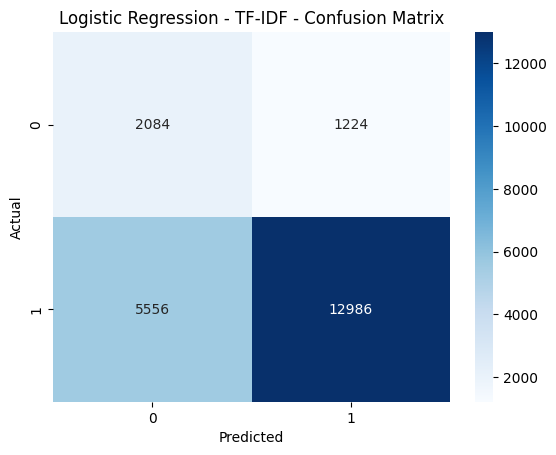

In [ ]:
#Logistic Regression with GridSearchCV
lr = LogisticRegression(max_iter=1000, class_weight='balanced')

lr_params = {
    'C': [0.1, 1, 10]
}

lr_grid = GridSearchCV(
    lr,
    lr_params,
    cv=3,
    scoring='f1',
    n_jobs=-1
)

lr_grid.fit(X_train_uni, y_train)

best_lr = lr_grid.best_estimator_

print("Best Parameters:", lr_grid.best_params_)

evaluate_model(
    "Logistic Regression - TF-IDF",
    best_lr,
    X_test_uni,
    y_test
)

Best Parameters: {'C': 0.1}

Model: Linear SVM - TF-IDF
Accuracy: 0.6900686498855835
Precision: 0.9143199098845396
Recall: 0.7004098802718154
F1 Score: 0.7931961155560985

Classification Report:
              precision    recall  f1-score   support

           0       0.27      0.63      0.38      3308
           1       0.91      0.70      0.79     18542

    accuracy                           0.69     21850
   macro avg       0.59      0.67      0.59     21850
weighted avg       0.82      0.69      0.73     21850



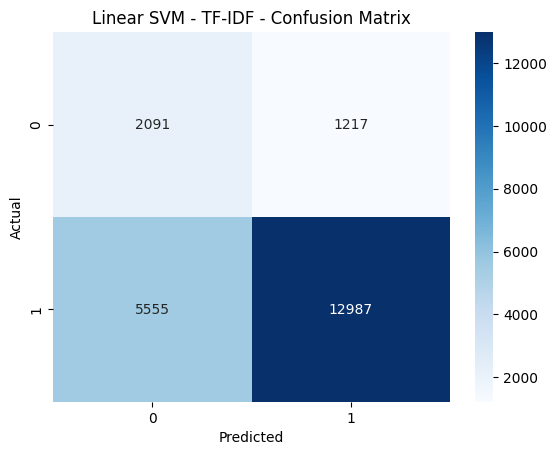

In [ ]:
#SVM with GridSearchCV
svm = LinearSVC(class_weight='balanced')

svm_params = {
    'C': [0.1, 1, 10]
}

svm_grid = GridSearchCV(
    svm,
    svm_params,
    cv=3,
    scoring='f1',
    n_jobs=-1
)

svm_grid.fit(X_train_uni, y_train)

best_svm = svm_grid.best_estimator_

print("Best Parameters:", svm_grid.best_params_)

evaluate_model(
    "Linear SVM - TF-IDF",
    best_svm,
    X_test_uni,
    y_test
)


Model: Logistic Regression - GloVe
Accuracy: 0.6409153318077804
Precision: 0.9094319399785638
Recall: 0.640653651170316
F1 Score: 0.7517402860397419

Classification Report:
              precision    recall  f1-score   support

           0       0.24      0.64      0.35      3308
           1       0.91      0.64      0.75     18542

    accuracy                           0.64     21850
   macro avg       0.58      0.64      0.55     21850
weighted avg       0.81      0.64      0.69     21850



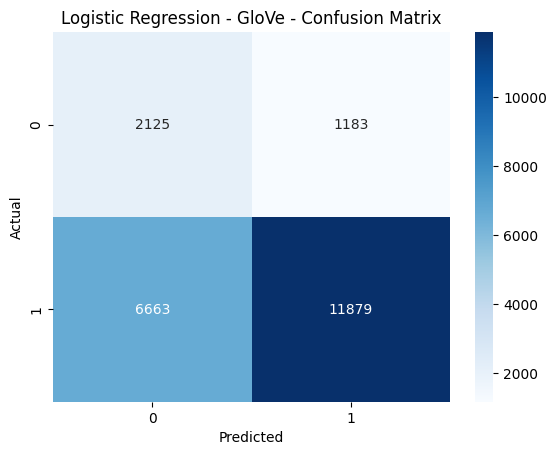

In [ ]:
#Logistic Regression using Word Embeddings
lr_w2v = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

lr_w2v.fit(X_train_w2v, y_train)

evaluate_model(
    "Logistic Regression - GloVe",
    lr_w2v,
    X_test_w2v,
    y_test
)

In [ ]:
#Deep Learning Model – TensorFlow/Keras
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Dense, Dropout, Concatenate
)
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
#Prepare TF-IDF input for deep learning
tfidf_dl = TfidfVectorizer(
    max_features=1000,
    ngram_range=(1, 2)
)

X_train_tfidf_dl = tfidf_dl.fit_transform(X_train).toarray()
X_test_tfidf_dl = tfidf_dl.transform(X_test).toarray()

print("TF-IDF training shape:", X_train_tfidf_dl.shape)

TF-IDF training shape: (87398, 1000)


In [ ]:
#Prepare Word Embedding input
X_train_embedding = X_train_w2v.astype('float32')
X_test_embedding = X_test_w2v.astype('float32')

X_train_tfidf_dl = X_train_tfidf_dl.astype('float32')
X_test_tfidf_dl = X_test_tfidf_dl.astype('float32')

y_train_dl = y_train.values.astype('float32')
y_test_dl = y_test.values.astype('float32')

In [ ]:
#Functional API model
# First input: TF-IDF
tfidf_input = Input(shape=(1000,), name='tfidf_input')

tfidf_branch = Dense(128, activation='relu')(tfidf_input)
tfidf_branch = Dropout(0.3)(tfidf_branch)

# Second input: GloVe embedding
embedding_input = Input(shape=(100,), name='embedding_input')

embedding_branch = Dense(64, activation='relu')(embedding_input)
embedding_branch = Dropout(0.3)(embedding_branch)

# Combine both inputs
combined = Concatenate()([tfidf_branch, embedding_branch])

# Final dense layers
x = Dense(64, activation='relu')(combined)
x = Dropout(0.3)(x)

output = Dense(1, activation='sigmoid')(x)

# Create model
dl_model = Model(
    inputs=[tfidf_input, embedding_input],
    outputs=output
)

dl_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ tfidf_input         │ (None, 1000)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_input     │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    128,128 │ tfidf_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      6,464 │ embedding_input[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 192)       │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │     12,352 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         65 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 147,009 (574.25 KB)

 Trainable params: 147,009 (574.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Compile model
dl_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
# Train deep learning model

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = dl_model.fit(
    [X_train_tfidf_dl, X_train_embedding],
    y_train_dl,
    validation_split=0.2,
    epochs=5,
    batch_size=64,
    callbacks=[early_stop]
)


AttributeError: 'KeyedVectors' object has no attribute 'fit'